---

<br>

# MODULE 5: MULTIPLE LINEAR REGRESSION

<br>

---

In this section we'll build **multiple linear regression** models using more than one feature, evaluate the model fit, perform variable selection, and compare models using error metrics.

<br>

## Topics We'll Cover

>- Multiple Regression
>
>- Variable Selection
>
>- Mean Error Metrics

<br>

## Goals for This Section

>- Learn how to fit and interpret multiple linear regression models in Python
>
>- Walk through methods of performing variable selection, ensuring model variables add value
>
>- Compare the predictive accuracy across models using mean error metrics like **MAE** and **RMSE**
>

<br><br>

<br><br>

---

## 01.Multiple Linear Regression Equation

<br>

---

**Multiple Linear Regression** models use *multiple features* to predict the target. In other words, it's the same linear regression model, but with additional "X" variables.

<br>

*Simple Linear Regression:*

$$\LARGE y = \beta_0 + \beta_1 \cdot x + \epsilon$$ 

<br>

*Multiple Linear Regression:*

$$\LARGE y = \beta_0 + \beta_1 \cdot x_1 + \beta_2 \cdot x_2 + \beta_3 \cdot x_3 + \cdot\cdot\cdot + \beta_k \cdot x_k + \epsilon$$

<br>

- Instead of just one 'X', we have a **whole set of features** (*and associated coefficients*) to help predict the target **"y"**.

- To visualize how a multiple linear regression model works with 2 features, imagine fitting a plane (*instead of a line*) through a 3D scatterplot:

>---
>
>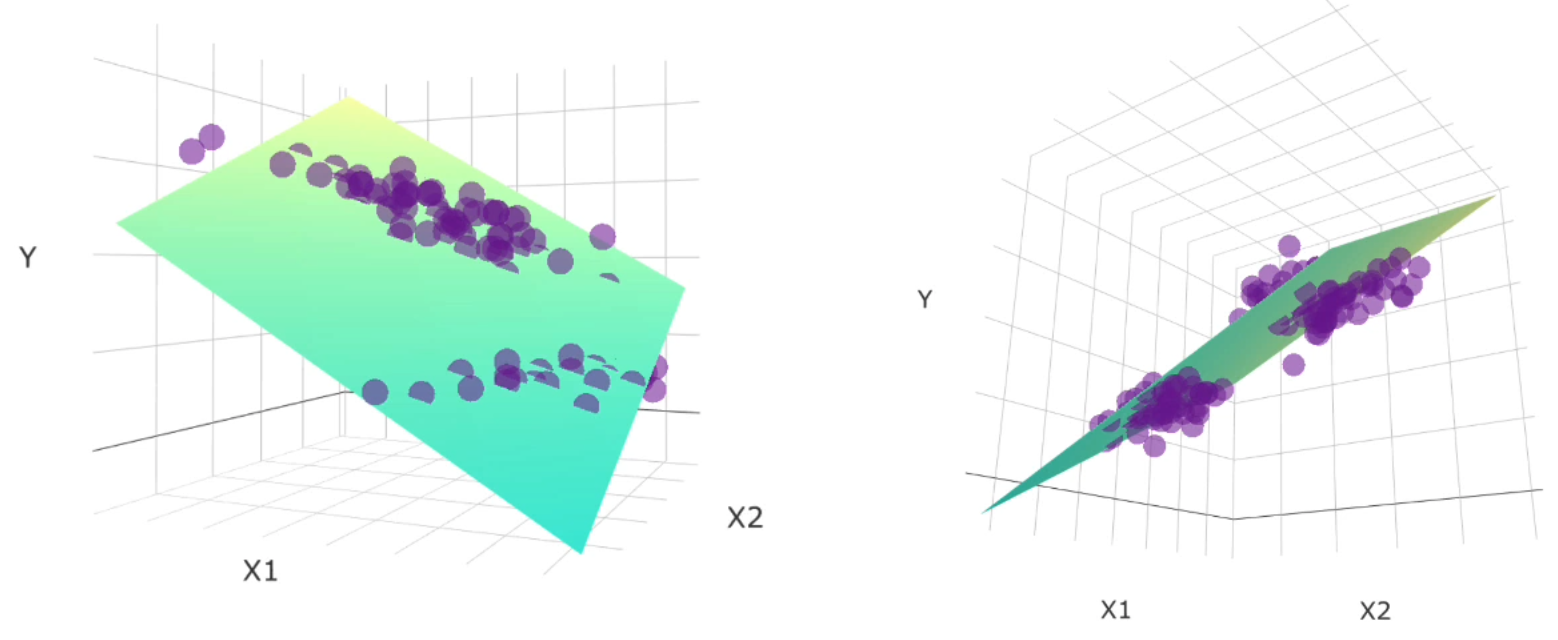
>
>---

<br><br>

---

## 02.Fitting a Multiple Regression

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm

In [2]:
# import the dataset
insurance = pd.read_csv('../datasets/insurance.csv')
insurance.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
# let's re-crate our model
features = ['age', 'bmi']

X = sm.add_constant(insurance[features])
y = insurance['charges']

model = sm.OLS(y, X).fit()

model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.117
Model:                            OLS   Adj. R-squared:                  0.116
Method:                 Least Squares   F-statistic:                     88.60
Date:                Wed, 11 Nov 2026   Prob (F-statistic):           7.39e-37
Time:                        11:58:41   Log-Likelihood:                -14394.
No. Observations:                1338   AIC:                         2.879e+04
Df Residuals:                    1335   BIC:                         2.881e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -6424.8046   1744.091     -3.684      0.000   -9846.262   -3003.347
age          241.9308     22.298     10.850      0.000     198.187     285.674
bmi          332.9651     51.374      6.481      0.000     232.182     433.748
==============================================================================
Omnibus:                      321.874   Durbin-Watson:                   2.010
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              592.574
Skew:                           1.511   Prob(JB):                    2.11e-129
Kurtosis:                       4.223   Cond. No.                         287.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

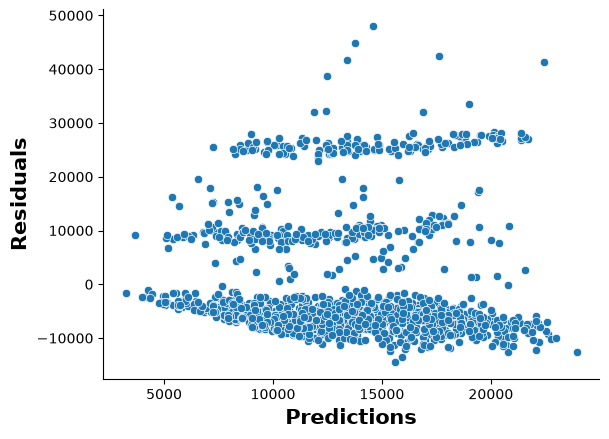

In [4]:
sns.scatterplot(x=model.predict(), y=model.resid)

plt.xlabel('Predictions', fontsize=15, fontweight='bold')
plt.ylabel('Residuals', fontsize=15, fontweight='bold')

sns.despine()

<br><br>

---

## 03.Interpreting Multiple Linear Regression Models

>---
>
>Result from the training with stastsmodels:
>
>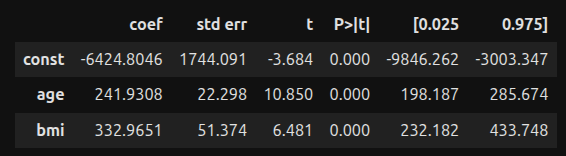
>
>---

<br><br>

**COEFICIENTS AND FORMULA**

From the fitted model we get...

$$\LARGE \hat y = -6424.80 + 241.93(age) + 332.96(bmi)$$

>---
>
>- Technically , a **0 age** with **0 bmi** is predicted to cost `-6424.8 USD`
>  
>- An increase in **age by 1** corresponds to a `241.93 USD` increase in price, **holding age constant**
>
>- An increase in **bmi by 1** corresponds to a `332.96 USD` increase in prcie, **holding bmi constant**
>
>---


<br><br>

---

## 04.Variable Selection

<br>

>---
>
>**Variable Selection** is a critical part of the modelling process that helps reduce complexity by only including features that help meet the model's goal.
>
>  - *Do new variables improve model accuracy?* (critical for prediction)
>
>  - *Is each variable statistically significant?* (critical for inference)
>
>  - *Do new variables make the model more challenging to interpret or explain to stakeholders?*
>
>---



In [5]:
features = ['age', 'bmi', 'children']

X = sm.add_constant(insurance[features])
y = insurance['charges']

model = sm.OLS(y, X).fit()

model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.120
Model:                            OLS   Adj. R-squared:                  0.118
Method:                 Least Squares   F-statistic:                     60.69
Date:                Wed, 11 Nov 2026   Prob (F-statistic):           8.80e-37
Time:                        11:58:42   Log-Likelihood:                -14392.
No. Observations:                1338   AIC:                         2.879e+04
Df Residuals:                    1334   BIC:                         2.881e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -6916.2433   1757.480     -3.935      0.000   -1.04e+04   -3468.518
age          239.9945     22.289     10.767      0.000     196.269     283.720
bmi          332.0834     51.310      6.472      0.000     231.425     432.741
children     542.8647    258.241      2.102      0.036      36.261    1049.468
==============================================================================
Omnibus:                      325.395   Durbin-Watson:                   2.012
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              603.372
Skew:                           1.520   Prob(JB):                    9.54e-132
Kurtosis:                       4.255   Cond. No.                         290.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

<br><br>

---

## 05.Mean Error Metrics

<br>

>`Mean Error Metrics` measure how well your regression model fits in the units of our target, as opposed to how well it explains variance (**like R Squared**).
>
>  - The most common are **Mean Absolute Error** (MAE) and **Root Mean Squared Error** (RMSE).
>
>  - They are used to compare model fit across models (*the lower the better*)
>

<br>

>- **`MAE` - Mean Absolute Error is the average of the **absolute** distance between actual & predicted values:**
>
>$$\LARGE \frac{\sum_i |y_i - \hat y_i|}{n}$$
>

<br>

>- **`MSE` - Mean Squared Error is the average of the squared distance between actual and predicted values:**
>
>$$\LARGE \frac{\sum_i (y_i - \hat y_i)^2}{n}$$

<br>

>- **`RMSE` - Root Mean Squared Error is the squared root of MSE, it's used to return to the target's original units (*like MAE*):**
>
>$$\LARGE \sqrt{\frac{\sum_i (y_i - \hat y_i)^2}{n}}$$
>
>`NOTE: RMSE is more sensitive to outliers`, so it is preferred over MAE in situations where they are particularly undesirable.

>---
>
>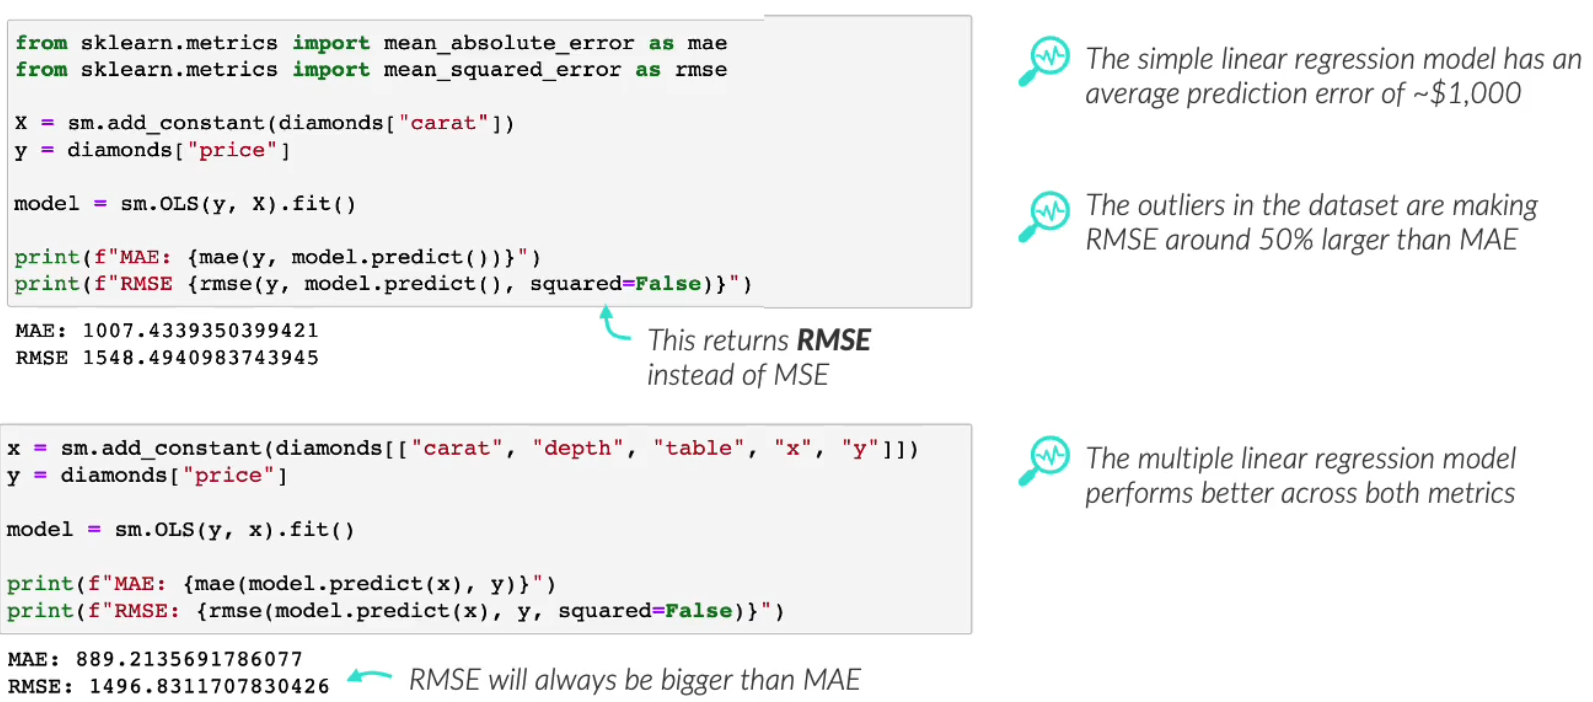
>
>`NOTE:` the result from MAE and RMSE is in the same amount or units of the target. and it's no a percentage like we saw on **statsmodels** model.summary()
>
>---

In [6]:
# Time to start calculation now with Scikit-Learn
from sklearn.metrics import mean_absolute_error as mae
from sklearn.metrics import root_mean_squared_error as rmse
from sklearn.metrics import r2_score as r2

results = pd.DataFrame({'MAE':mae(y, model.predict()),
                        'RMSE':rmse(y, model.predict()),
                        'R2':r2(y, model.predict())}, index=['USD']).round(4)

results

,MAE,RMSE,R2
USD,9015.4422,11355.3179,0.1201
